# 🧪 SportSnap — FILE 2/2: Thí nghiệm bổ sung (Mục 12)

Đây là **file 2/2** sau khi tách notebook gốc. File này **không huấn luyện lại 3 mô hình chính**: nó nạp checkpoint rồi chạy các thí nghiệm bổ sung (mục 5.9 báo cáo): lặp nhiều seed, test mở rộng + Wilson CI, pHash, Top-1/Top-5 ảnh ngoài, thời gian CPU, ablation che nền/che người, Grad-CAM đối chiếu.

**Chuẩn bị dữ liệu & checkpoint**
- **Trên máy cục bộ (`d:\tgmt`):** notebook tự nhận `./models/` (5 file `.keras` từ `models.zip`), `./datasets/sports-classification/` (`train`/`valid`/`test`) và `./datasets/anh-ngoai/` (cho Mục 12.4).
- **Trên Kaggle (Add Input):** thêm Dataset `data-sportsnap` và Kaggle Model chứa các checkpoint (`.keras`), bật GPU và bật **Internet** nếu cần cài `imagehash` (12.3) hoặc tải trọng số DeepLabV3 (12.6).

**Thứ tự chạy:** chạy từ trên xuống đến hết **Mục 5 (Khôi phục mô hình)** để kiểm tra điểm test khớp khoảng 0,80 / 0,97 / 1,00, rồi bật **từng cờ một** ở **Mục 6 (Cờ bật/tắt)** và chạy ô thí nghiệm tương ứng. **Không** bật tất cả cờ cùng lúc (multi-seed chạy nhiều giờ).

Gợi ý thứ tự: 12.3 pHash → 12.4 Top-5 ảnh ngoài → 12.5 thời gian CPU → 12.6 ablation (chạy 2 lần: ResNet50 và MobileNetV2) → 12.2 test mở rộng → 12.1 multi-seed.

---

## 1. Import thư viện

In [24]:
# Cài nếu thiếu (cần Internet trên Kaggle):
# !pip install -q imagehash

In [25]:
import os, glob, random, pathlib, math, json, time, gc, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.19.0
GPU: []


## 2. Cấu hình & tìm checkpoint

In [26]:
# ==== TỰ ĐỘNG DÒ TÌM ĐƯỜNG DẪN DỮ LIỆU & CHECKPOINT (CỤC BỘ / KAGGLE / COLAB) ====
def find_project_root():
    cwd = pathlib.Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        if (base / "datasets").exists() or (base / "models").exists():
            return str(base)
    return r"d:\tgmt" if os.path.exists(r"d:\tgmt") else str(cwd)

PROJECT_ROOT = find_project_root()

def auto_find_data_root():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "train" in dirs:
                return root
    cands = [
        os.path.join(PROJECT_ROOT, "datasets", "sports-classification"),
        "./datasets/sports-classification",
        "../datasets/sports-classification",
        r"d:\tgmt\datasets\sports-classification",
        r"d:\tgmt\datasets\gpiosenka\sports-classification",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap",
        "/kaggle/input/datasets/gpiosenka/sports-classification",
    ]
    for p in cands:
        if os.path.exists(p):
            return os.path.abspath(p)
    return os.path.join(PROJECT_ROOT, "datasets", "sports-classification")

DATA_ROOT = auto_find_data_root()
print(f"[SportSnap] PROJECT_ROOT: {PROJECT_ROOT}")
print(f"[SportSnap] Sử dụng DATA_ROOT: {DATA_ROOT}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_TOP_CLASSES = 20   # 20 môn thể thao chuẩn đề tài

LABEL_SMOOTHING = 0.1

REQUIRED_CKPTS = (
    "cnn_scratch_best.keras",
    "MobileNetV2_finetune_best.keras",
    "ResNet50_finetune_best.keras",
)

def find_model_dir():
    """Tìm thư mục chứa checkpoint .keras (cục bộ ./models hoặc Kaggle Input)."""
    cands = [
        os.path.join(PROJECT_ROOT, "models"),
        "./models",
        "../models",
        ".",
        "/kaggle/working",
    ]
    for d in cands:
        if all(os.path.exists(os.path.join(d, fn)) for fn in REQUIRED_CKPTS):
            return os.path.abspath(d)
    hits = glob.glob("/kaggle/input/**/MobileNetV2_finetune_best.keras", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

MODEL_DIR = find_model_dir()
print("[SportSnap] MODEL_DIR:", MODEL_DIR)
assert MODEL_DIR is not None, (
    "Không thấy đủ 3 checkpoint (.keras) trong ./models, thư mục hiện tại hoặc /kaggle/input."
)

[SportSnap] PROJECT_ROOT: D:\tgmt
[SportSnap] Sử dụng DATA_ROOT: D:\tgmt\datasets\sports-classification
[SportSnap] MODEL_DIR: D:\tgmt\models


## 3. Dữ liệu (chỉ phần nền cần cho Mục 12)

In [27]:
def find_dataset_dirs(root):
    """Dò tự động các thư mục train/valid(hoặc val)/test bên trong root (kể cả lồng nhau)."""
    candidates = {"train": None, "valid": None, "test": None}
    aliases = {"train": ["train"], "valid": ["valid", "val", "validation"], "test": ["test"]}
    for dirpath, dirnames, filenames in os.walk(root):
        base = os.path.basename(dirpath).lower()
        for key, names in aliases.items():
            if base in names and candidates[key] is None:
                candidates[key] = dirpath
    return candidates

dirs = find_dataset_dirs(DATA_ROOT)
print("Đã dò được:")
for k, v in dirs.items():
    print(f"  {k}: {v}")

assert dirs["train"] is not None, "Không tìm thấy thư mục train/ — hãy kiểm tra lại DATA_ROOT."
TRAIN_DIR = dirs["train"]
VALID_DIR = dirs["valid"] if dirs["valid"] else dirs["test"]
TEST_DIR = dirs["test"] if dirs["test"] else dirs["valid"]
print("\nTRAIN_DIR:", TRAIN_DIR)
print("VALID_DIR:", VALID_DIR)
print("TEST_DIR :", TEST_DIR)


Đã dò được:
  train: D:\tgmt\datasets\sports-classification\train
  valid: D:\tgmt\datasets\sports-classification\valid
  test: D:\tgmt\datasets\sports-classification\test

TRAIN_DIR: D:\tgmt\datasets\sports-classification\train
VALID_DIR: D:\tgmt\datasets\sports-classification\valid
TEST_DIR : D:\tgmt\datasets\sports-classification\test


In [28]:
def class_counts(directory):
    classes = sorted([d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))])
    counts = {}
    for c in classes:
        n = len(glob.glob(os.path.join(directory, c, "*")))
        counts[c] = n
    return pd.Series(counts).sort_values(ascending=False)

train_counts = class_counts(TRAIN_DIR)
print(f"Tổng số lớp trong tập train: {len(train_counts)}")
train_counts.head(20)


Tổng số lớp trong tập train: 20


archery                 300
baseball                300
basketball              300
boxing                  300
canoe slamon            300
field hockey            300
figure skating women    300
football                300
formula 1 racing        300
golf                    300
high jump               300
hockey                  300
olympic wrestling       300
polo                    300
roller derby            300
rollerblade racing      300
swimming                300
tennis                  300
uneven bars             300
volleyball              300
dtype: int64

In [29]:
# Chọn NUM_TOP_CLASSES môn thể thao có nhiều ảnh nhất (đúng theo mục tiêu: 15-20 môn phổ biến)
if NUM_TOP_CLASSES is not None:
    SELECTED_CLASSES = list(train_counts.head(NUM_TOP_CLASSES).index)
else:
    SELECTED_CLASSES = list(train_counts.index)

print(f"Số lớp được chọn: {len(SELECTED_CLASSES)}")
print(SELECTED_CLASSES)


Số lớp được chọn: 20
['archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'football', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'rollerblade racing', 'swimming', 'tennis', 'uneven bars', 'volleyball']


In [30]:
def make_filtered_dataset(directory, classes, img_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        class_names=sorted(classes),
        image_size=img_size,
        batch_size=batch_size,
        shuffle=shuffle,
        seed=SEED,
    )
    return ds

train_ds_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
valid_ds_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
test_ds_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Số lớp:", NUM_CLASSES)
print(CLASS_NAMES)


Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Số lớp: 20
['archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'football', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'rollerblade racing', 'swimming', 'tennis', 'uneven bars', 'volleyball']


In [31]:
# ==== NÂNG CẤP V3: BỘ TĂNG CƯỜNG DỮ LIỆU ĐẶC TRỊ CAMERA (CAMERA-RESILIENT) ====
# Chống lóa sáng màn hình điện thoại, chịu nghiêng góc, thu phóng và thích ứng ánh sáng thực tế
data_augmentation = keras.Sequential([
    # 1. Biến đổi hình học & góc nhìn (Geometric)
    layers.RandomFlip("horizontal"),                       # Lật ngang (trái/phải)
    layers.RandomRotation(0.15),                           # Xoay nghiêng góc ±15% (~54 độ)
    layers.RandomZoom(height_factor=(-0.2, 0.2)),          # Thu phóng xa/gần (chụp toàn cảnh hoặc cận cảnh)
    layers.RandomTranslation(0.10, 0.10),                  # Dịch chuyển vị trí chủ thể lệch tâm

    # 2. Xử lý quang học & cảm biến camera (Photometric & Sensor)
    layers.RandomContrast(0.30),                           # Chống lóa sáng màn hình và đèn flash
    layers.RandomBrightness(0.30, value_range=(0, 255)),   # Thích nghi phòng tối, ngoài trời nắng
    layers.GaussianNoise(0.05),                            # Giả lập nhiễu hạt sensor webcam/điện thoại
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE
SHUFFLE_BUFFER = 1000

def prep_dataset(ds, augment=False, preprocess_fn=None, cache=True, onehot=False):
    """onehot=True: đổi nhãn int -> one-hot (cần cho CategoricalCrossentropy có label smoothing).
    Chỉ dùng onehot cho tập train/valid khi fit; tập test giữ nhãn int để dùng với sklearn."""
    if cache:
        ds = ds.cache()
    if augment:
        ds = ds.unbatch().shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    if preprocess_fn is not None:
        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    if onehot:
        ds = ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


## 4. Hàm dựng mô hình, tiện ích huấn luyện, Grad-CAM

In [32]:
def conv_bn(x, filters, name=None):
    x = layers.Conv2D(filters, 3, activation="relu", padding="same", name=name)(x)
    return layers.BatchNormalization()(x)   # BN đặt SAU ReLU -> lớp Conv "last_conv" vẫn là mục tiêu Grad-CAM hợp lệ

def build_cnn_scratch(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = conv_bn(x, 32);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 64);  x = conv_bn(x, 64);   x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 128); x = conv_bn(x, 128);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 256, name="last_conv");     x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Scratch")


def build_transfer_model(base_class, input_shape, num_classes, name):
    base = base_class(include_top=False, weights="imagenet", input_shape=input_shape)
    base.trainable = False  # đóng băng ban đầu, sẽ fine-tune sau
    inputs = keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, base


INPUT_SHAPE = IMG_SIZE + (3,)


In [33]:
EPOCHS_HEAD = 10       # huấn luyện đầu (frozen base với 2 mô hình transfer)
EPOCHS_FINETUNE = 25   # fine-tune thêm (EarlyStopping sẽ dừng đúng lúc)
FINETUNE_LR = 3e-5     # đỉnh của cosine decay khi fine-tune
UNFREEZE = {"MobileNetV2": 80, "ResNet50": 120}   # số lớp cuối của base được mở khóa

def make_loss():
    return keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

def cosine_schedule(peak_lr, total_epochs, min_lr=1e-7, warmup_epochs=1):
    def fn(epoch):
        if epoch < warmup_epochs:
            return peak_lr * (epoch + 1) / (warmup_epochs + 1)
        t = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * min(1.0, t)))
    return fn

def get_callbacks(name, checkpoint=True, plateau=True, lr_fn=None, patience=8):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if checkpoint:
        cbs.append(keras.callbacks.ModelCheckpoint(f"{name}_best.keras", monitor="val_loss", save_best_only=True))
    if plateau:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2))
    if lr_fn is not None:
        cbs.append(keras.callbacks.LearningRateScheduler(lr_fn))
    return cbs

def freeze_batchnorm(base_model):
    """Đóng băng BatchNorm khi fine-tune để không phá thống kê ImageNet trên tập nhỏ."""
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def unfreeze_top_layers(base_model, n_layers):
    """Progressive unfreezing: chỉ mở khóa n_layers cuối của base, BN vẫn đóng băng."""
    base_model.trainable = True
    for layer in base_model.layers[:-n_layers]:
        layer.trainable = False
    freeze_batchnorm(base_model)

def quick_acc(model, ds):
    """Accuracy trên ds có nhãn int (test), không phụ thuộc loss của model."""
    y = np.concatenate([b.numpy() for _, b in ds])
    return accuracy_score(y, np.argmax(model.predict(ds, verbose=0), axis=1))

def train_transfer_model(base_class, preprocess_fn, name, train_raw, valid_raw,
                         unfreeze_n, head_eval_ds=None, checkpoint=True,
                         epochs_head=None, epochs_ft=None, verbose=1):
    """Huấn luyện 2 giai đoạn: (1) head với base đóng băng, (2) fine-tune top layers + cosine LR.
    Trả về (model, base, history_gộp, info). info['head_test_acc'] = accuracy khi CHỈ train head (Frozen)."""
    epochs_head = EPOCHS_HEAD if epochs_head is None else epochs_head
    epochs_ft = EPOCHS_FINETUNE if epochs_ft is None else epochs_ft
    model, base = build_transfer_model(base_class, INPUT_SHAPE, NUM_CLASSES, f"{name}_Transfer")
    tr = prep_dataset(train_raw, augment=True,  preprocess_fn=preprocess_fn, onehot=True)
    va = prep_dataset(valid_raw, augment=False, preprocess_fn=preprocess_fn, onehot=True)

    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
    h1 = model.fit(tr, validation_data=va, epochs=epochs_head, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_head", checkpoint=checkpoint))
    info = {}
    if head_eval_ds is not None:
        info["head_test_acc"] = quick_acc(model, head_eval_ds)

    unfreeze_top_layers(base, unfreeze_n)
    model.compile(optimizer=keras.optimizers.Adam(FINETUNE_LR), loss=make_loss(), metrics=["accuracy"])
    h2 = model.fit(tr, validation_data=va, epochs=epochs_ft, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_finetune", checkpoint=checkpoint, plateau=False,
                                           lr_fn=cosine_schedule(FINETUNE_LR, epochs_ft), patience=10))
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history if k in h2.history}
    return model, base, hist, info


In [34]:
def get_last_conv_layer_name(model):
    """Lớp mục tiêu Grad-CAM.
    - Mạng nền lồng bên trong (MobileNetV2 / ResNet50): lớp CUỐI của base = đầu ra ngay trước GAP
      ('out_relu' của MobileNetV2, 'conv5_block3_out' của ResNet50).
    - CNN từ đầu: lớp 'last_conv'."""
    for layer in reversed(model.layers):
        if hasattr(layer, "layers"):
            return layer.layers[-1].name
    return "last_conv"


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Tìm layer conv cuối: có thể nằm trực tiếp trong `model` (CNN từ đầu),
    # hoặc lồng bên trong một submodel pretrained (base MobileNetV2/ResNet50).
    target_layer = None
    base_submodel = None
    for layer in model.layers:
        if layer.name == last_conv_layer_name:
            target_layer = layer
            break
    if target_layer is None:
        for layer in model.layers:
            if hasattr(layer, "get_layer"):
                try:
                    target_layer = layer.get_layer(last_conv_layer_name)
                    base_submodel = layer
                    break
                except ValueError:
                    continue
    if target_layer is None:
        raise ValueError(f"Không tìm thấy layer '{last_conv_layer_name}' trong model.")

    if base_submodel is None:
        # Trường hợp CNN từ đầu: conv layer nằm ngay trong graph của `model`,
        # nên có thể dựng grad_model 1 giai đoạn như bình thường.
        grad_model = keras.Model(inputs=model.inputs, outputs=[target_layer.output, model.output])
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(img_array)
            if pred_index is None:
                pred_index = tf.argmax(predictions[0])
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)
    else:
        # Trường hợp transfer learning: conv layer nằm trong submodel pretrained (base),
        # được gọi như 1 layer duy nhất trong `model` -> không thể dựng 1 grad_model
        # bắc cầu qua 2 graph khác nhau. Tách thành 2 giai đoạn:
        #   (1) conv_model: input của base -> output của conv layer cuối
        #   (2) classifier_model: các layer sau base (GAP, Dropout, Dense...) áp lên conv_outputs
        conv_model = keras.Model(base_submodel.input, target_layer.output)

        classifier_layers = [l for l in model.layers if l is not model.layers[0] and l is not base_submodel]
        classifier_input = keras.Input(shape=conv_model.output.shape[1:])
        y = classifier_input
        for layer in classifier_layers:
            y = layer(y)
        classifier_model = keras.Model(classifier_input, y)

        with tf.GradientTape() as tape:
            conv_outputs = conv_model(img_array)
            tape.watch(conv_outputs)
            predictions = classifier_model(conv_outputs)
            if pred_index is None:
                pred_index = tf.argmax(predictions[0])
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def overlay_gradcam(img_rgb, heatmap, alpha=0.55, threshold=0.18):
    """Grad-CAM nang cao: Loc bo suong mu xanh lam o nen (alpha=0 khi heatmap duoi nguong).
    Vung AI chu y cao se duoc phu mau ruc ro va sac net tren anh goc.
    """
    h, w = img_rgb.shape[:2]
    heatmap_resized = cv2.resize(heatmap, (w, h))
    mask = np.clip((heatmap_resized - threshold) / (1.0 - threshold + 1e-8), 0.0, 1.0)
    mask = (mask * alpha)[..., np.newaxis]
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    return np.uint8(img_rgb * (1.0 - mask) + heatmap_color * mask)


In [35]:
def show_gradcam_examples(model, ds_raw, preprocess_fn, class_names, n=6, seed=SEED):
    """Chọn ngẫu nhiên n ảnh test (test_ds_raw không shuffle nên take() chỉ ra vài ảnh đầu cùng 1 lớp)."""
    last_conv_name = get_last_conv_layer_name(model)
    all_imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    all_labels = np.concatenate([labels.numpy() for _, labels in ds_raw])
    chosen = np.random.RandomState(seed).choice(len(all_imgs), min(n, len(all_imgs)), replace=False)

    cols = max(1, math.ceil(len(chosen) / 2))
    rows = math.ceil(len(chosen) / cols)
    plt.figure(figsize=(5 * cols, 4 * rows))
    for k, idx in enumerate(chosen):
        img_rgb = all_imgs[idx].astype("uint8")
        x = tf.expand_dims(all_imgs[idx], 0)
        # CNN_Scratch đã có sẵn lớp Rescaling(1/255) bên trong -> KHÔNG chia 255 thêm lần nữa
        x = preprocess_fn(x) if preprocess_fn else x
        heatmap, pred_idx = make_gradcam_heatmap(x, model, last_conv_name)
        overlay = overlay_gradcam(img_rgb, heatmap)

        plt.subplot(rows, cols, k + 1)
        plt.imshow(overlay)
        true_label = class_names[all_labels[idx]]
        pred_label = class_names[pred_idx]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"Thực: {true_label}\nDự đoán: {pred_label}", color=color, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


## 5. Khôi phục mô hình từ checkpoint
Không huấn luyện lại. Sau ô này kiểm tra điểm test khớp ~0,80 / 0,97 / 1,00.

In [36]:
# ==== KHÔI PHỤC 3 MÔ HÌNH TỪ CHECKPOINT (không huấn luyện lại) ====
def _load_model(fn):
    m = keras.models.load_model(os.path.join(MODEL_DIR, fn), compile=False)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
    return m

cnn_scratch     = _load_model("cnn_scratch_best.keras")
mobilenet_model = _load_model("MobileNetV2_finetune_best.keras")
resnet_model    = _load_model("ResNet50_finetune_best.keras")

test_ds       = prep_dataset(test_ds_raw, augment=False)
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
test_ds_res   = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds      = prep_dataset(valid_ds_raw, augment=False, onehot=True)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)
valid_ds_res  = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

# Chọn mô hình tốt nhất theo VALIDATION (giống Mục 9 file 1; hòa -> lấy mô hình đứng trước trong dict)
val_pairs = {
    "CNN_Scratch": (cnn_scratch, valid_ds),
    "MobileNetV2": (mobilenet_model, valid_ds_mnv2),
    "ResNet50":    (resnet_model, valid_ds_res),
}
val_acc = {n: m.evaluate(ds, verbose=0)[1] for n, (m, ds) in val_pairs.items()}
model_map = {"CNN_Scratch": cnn_scratch, "MobileNetV2": mobilenet_model, "ResNet50": resnet_model}
best_model_name = max(val_acc, key=val_acc.get)
best_model = model_map[best_model_name]
best_preprocess_fn = {"CNN_Scratch": None, "MobileNetV2": mnv2_preprocess, "ResNet50": resnet_preprocess}[best_model_name]

# Kiểm tra nhanh trên test: phải khớp khoảng 0.80 / 0.97 / 1.00 như lần huấn luyện
test_pairs = {"CNN_Scratch": (cnn_scratch, test_ds), "MobileNetV2": (mobilenet_model, test_ds_mnv2), "ResNet50": (resnet_model, test_ds_res)}
for n, (m, ds) in test_pairs.items():
    print(f"{n}: val={val_acc[n]:.4f} | test={quick_acc(m, ds):.4f}")
print("Mô hình tốt nhất theo Val:", best_model_name)


CNN_Scratch: val=0.7700 | test=0.7900
MobileNetV2: val=0.9800 | test=0.9700
ResNet50: val=0.9700 | test=1.0000
Mô hình tốt nhất theo Val: MobileNetV2


## 6. Cờ bật/tắt thí nghiệm Mục 12

In [ ]:
# ==== CỜ BẬT/TẮT CÁC THÍ NGHIỆM MỤC 12 (bật TỪNG cái một, chạy xong rồi mới bật cái kế tiếp) ====
RUN_PHASH_CHECK    = True    # 12.3 – nhanh: kiểm tra trùng ảnh bằng pHash
RUN_ABLATION       = True   # 12.6 – cần torch/torchvision + trọng số DeepLabV3 (cần Internet)
RUN_EXTENDED_TEST  = True   # 12.2 – huấn luyện 1 lần MobileNetV2 trên 80% train
RUN_MULTI_SEED     = True   # 12.1 – 5 seed MobileNetV2 + 3 seed ResNet50 (nhiều giờ)
RUN_MULTI_SEED_CNN = True   # 12.1 – thêm 5 seed CNN_Scratch × 50 epoch (rất lâu)

# Mô hình dùng cho ablation 12.6: "best" | "ResNet50" | "MobileNetV2"
# Cô yêu cầu đo cả hai mô hình -> chạy ô 12.6 hai lần, mỗi lần đổi giá trị này.
ABLATION_MODEL = "ResNet50"

# Số epoch cho 12.1 & 12.2: None = dùng chuẩn EPOCHS_HEAD=10, EPOCHS_FINETUNE=25
SUPP_EPOCHS_HEAD = None
SUPP_EPOCHS_FT = None


## 12. Các thí nghiệm bổ sung & kiểm chứng nâng cao (Mục 5.9)

Các thí nghiệm phục vụ điền số liệu Bảng 5.10 và phân tích sâu:
- Các mục **12.1, 12.2** sử dụng trực tiếp `train_transfer_model`, `build_cnn_scratch` (từ Mục 4) và cờ `RUN_*` ở **Mục 6**.
- Các mục **12.3–12.7** dùng các mô hình đã khôi phục ở **Mục 5** (hoặc tự nạp lại từ `MODEL_DIR` ở `./models/` / Kaggle Input). Nếu chạy nhảy cóc chỉ các mục đánh giá nhanh, hãy chạy trước tối thiểu Mục **1, 2, 3, 4 và 6**.

In [38]:
# ==== HÀM HỖ TRỢ DÙNG CHUNG CHO MỤC 12 ====
VALID_IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

def eval_ds(model, ds_raw, pre=None):
    ds = prep_dataset(ds_raw, augment=False, preprocess_fn=pre, cache=False)
    y = np.concatenate([b.numpy() for _, b in ds_raw])
    p = np.argmax(model.predict(ds, verbose=0), axis=1)
    return accuracy_score(y, p), f1_score(y, p, average="macro")

def resolve_model_path(filenames):
    raw_dirs = [
        globals().get("MODEL_DIR"),
        os.path.join(PROJECT_ROOT, "models"),
        "./models",
        ".",
        "/kaggle/working",
    ]
    search_dirs = list(dict.fromkeys(os.path.abspath(d) for d in raw_dirs if d))
    for d in search_dirs:
        for fn in filenames:
            p = os.path.join(d, fn)
            if os.path.exists(p):
                return p
    return None

def warn_if_label_mismatch(model_path):
    model_dir = os.path.dirname(os.path.abspath(model_path))
    for lbl_cand in [
        os.path.join(model_dir, "labels.json"),
        os.path.join(model_dir, "class_names.json"),
    ]:
        if os.path.exists(lbl_cand):
            with open(lbl_cand, "r", encoding="utf-8") as f:
                ckpt_labels = json.load(f)
            if list(ckpt_labels) != list(CLASS_NAMES):
                diff_ckpt = sorted(set(ckpt_labels) - set(CLASS_NAMES))
                diff_curr = sorted(set(CLASS_NAMES) - set(ckpt_labels))
                print(
                    f"[Cảnh báo] Checkpoint '{model_path}' dùng bộ nhãn khác với CLASS_NAMES hiện tại! "
                    f"(Thừa trong checkpoint: {diff_ckpt}; mới trong dataset: {diff_curr})."
                )
            return

def get_or_load_best_model():
    if "best_model" in globals() and globals()["best_model"] is not None:
        pre = globals().get("best_preprocess_fn", mnv2_preprocess)
        name = globals().get("best_model_name", "MobileNetV2")
        return globals()["best_model"], pre, name

    p = resolve_model_path(["MobileNetV2_finetune_best.keras", "ResNet50_finetune_best.keras"])
    if p is None:
        raise FileNotFoundError("Không tìm thấy checkpoint đã lưu (MobileNetV2_finetune_best.keras / ResNet50_finetune_best.keras).")
    print(f"[SportSnap] Nạp model tốt nhất từ: {p}")
    warn_if_label_mismatch(p)
    is_res = "ResNet50" in os.path.basename(p)
    return (
        tf.keras.models.load_model(p, compile=False),
        resnet_preprocess if is_res else mnv2_preprocess,
        "ResNet50 (loaded)" if is_res else "MobileNetV2 (loaded)",
    )

def get_or_load_named_model(var_name, checkpoint_filenames):
    if var_name in globals() and globals()[var_name] is not None:
        return globals()[var_name]
    p = resolve_model_path(checkpoint_filenames)
    if p is not None:
        print(f"[SportSnap] Nạp {var_name} từ checkpoint: {p}")
        warn_if_label_mismatch(p)
        return tf.keras.models.load_model(p, compile=False)
    return None

### 12.1. Lặp nhiều hạt giống (MobileNetV2: 5 seed; ResNet50: 3 seed; CNN_Scratch: 5 seed)

In [39]:
if RUN_MULTI_SEED:
    # Đồng bộ lại dataset để mỗi seed không dùng nhầm iterator cũ
    ms_train_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    CFG_SEEDS = {
        "MobileNetV2": (MobileNetV2, mnv2_preprocess, 5),
        "ResNet50":    (ResNet50, resnet_preprocess, 3),
    }
    multi_seed_res = {}
    for name, (cls, pre, n_seed) in CFG_SEEDS.items():
        multi_seed_res[name] = []
        for s in range(n_seed):
            set_seed(100 + s)
            m, *_ = train_transfer_model(
                cls, pre, f"{name}_s{s}",
                ms_train_raw, ms_valid_raw, UNFREEZE[name],
                checkpoint=False,
                epochs_head=SUPP_EPOCHS_HEAD,
                epochs_ft=SUPP_EPOCHS_FT,
                verbose=0,
            )
            acc, f1 = eval_ds(m, ms_test_raw, pre)
            multi_seed_res[name].append((acc, f1))
            print(f"{name} seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
            del m
            keras.backend.clear_session()
            gc.collect()

    for k, v in multi_seed_res.items():
        a = np.array(v)
        print(
            f"{k}: acc {a[:,0].mean():.3f} ± {a[:,0].std(ddof=1):.3f} "
            f"(min {a[:,0].min():.2f}, max {a[:,0].max():.2f}) | "
            f"F1 {a[:,1].mean():.3f} ± {a[:,1].std(ddof=1):.3f}"
        )
else:
    print("RUN_MULTI_SEED = False -> bỏ qua thí nghiệm lặp nhiều hạt giống. Bật RUN_MULTI_SEED = True ở Mục 6 để chạy.")

Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


KeyboardInterrupt: 

#### CNN_Scratch (5 seed, mỗi seed 50 epoch)
Dùng lại kiến trúc `build_cnn_scratch` và lịch cosine LR của Mục 4 với `set_seed(100 + s)` (bật `RUN_MULTI_SEED = True` và `RUN_MULTI_SEED_CNN = True` ở Mục 6 để chạy).

In [ ]:
if RUN_MULTI_SEED and RUN_MULTI_SEED_CNN:
    ms_train_raw = globals().get("ms_train_raw") or make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = globals().get("ms_valid_raw") or make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = globals().get("ms_test_raw")  or make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    n_epochs_cnn = globals().get("EPOCHS_SCRATCH", 50)
    cnn_seed_res = []
    for s in range(5):
        set_seed(100 + s)
        m_cnn = build_cnn_scratch(INPUT_SHAPE, NUM_CLASSES)
        tr_c = prep_dataset(ms_train_raw, augment=True, onehot=True)
        va_c = prep_dataset(ms_valid_raw, augment=False, onehot=True)
        m_cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
        m_cnn.fit(
            tr_c, validation_data=va_c, epochs=n_epochs_cnn, verbose=0,
            callbacks=get_callbacks(
                f"cnn_scratch_s{s}", checkpoint=False, plateau=False,
                lr_fn=cosine_schedule(1e-3, n_epochs_cnn, min_lr=1e-6, warmup_epochs=2),
                patience=12,
            ),
        )
        acc, f1 = eval_ds(m_cnn, ms_test_raw, None)
        cnn_seed_res.append((acc, f1))
        print(f"CNN_Scratch seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
        del m_cnn, tr_c, va_c
        keras.backend.clear_session()
        gc.collect()

    a_cnn = np.array(cnn_seed_res)
    print(
        f"CNN_Scratch: acc {a_cnn[:,0].mean():.3f} ± {a_cnn[:,0].std(ddof=1):.3f} "
        f"(min {a_cnn[:,0].min():.2f}, max {a_cnn[:,0].max():.2f}) | "
        f"F1 {a_cnn[:,1].mean():.3f} ± {a_cnn[:,1].std(ddof=1):.3f}"
    )
else:
    print("Bỏ qua CNN_Scratch multi-seed (cần bật cả RUN_MULTI_SEED = True và RUN_MULTI_SEED_CNN = True ở Mục 6).")

Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


### 12.2. Tập test mở rộng (20% train, phân tầng); huấn luyện trên 80% còn lại

In [ ]:
if RUN_EXTENDED_TEST:
    ext_paths, ext_labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        fs = sorted(
            f for f in glob.glob(os.path.join(TRAIN_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        ext_paths += fs
        ext_labels += [i] * len(fs)

    p_tr, p_te, y_tr, y_te = train_test_split(
        ext_paths, ext_labels, test_size=0.2, stratify=ext_labels, random_state=SEED
    )
    print(f"Chia phân tầng từ train -> Train 80%: {len(p_tr)} ảnh | Test mở rộng 20%: {len(p_te)} ảnh")

    def to_ds(paths_list, labels_list, shuffle=False):
        def load(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y
        ds = tf.data.Dataset.from_tensor_slices((paths_list, labels_list)).map(load, num_parallel_calls=AUTOTUNE)
        if shuffle:
            ds = ds.shuffle(len(paths_list), seed=SEED)
        return ds.batch(BATCH_SIZE)

    tr80, te20 = to_ds(p_tr, y_tr, True), to_ds(p_te, y_te, False)
    set_seed(SEED)
    m_ext, *_ = train_transfer_model(
        MobileNetV2, mnv2_preprocess, "MNV2_ext",
        tr80, valid_ds_raw, UNFREEZE["MobileNetV2"],
        checkpoint=False,
        epochs_head=SUPP_EPOCHS_HEAD,
        epochs_ft=SUPP_EPOCHS_FT,
        verbose=0,
    )
    acc, f1 = eval_ds(m_ext, te20, mnv2_preprocess)
    n_te, z = len(y_te), 1.96
    lo = (acc + z*z/(2*n_te) - z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    hi = (acc + z*z/(2*n_te) + z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    print(f"Test mở rộng n={n_te}: acc {acc:.3f} | F1 {f1:.3f} | Wilson 95% CI [{lo:.3f}; {hi:.3f}]")
    del m_ext, tr80, te20
    keras.backend.clear_session()
    gc.collect()
else:
    print("RUN_EXTENDED_TEST = False -> bỏ qua thí nghiệm tập test mở rộng. Bật RUN_EXTENDED_TEST = True ở Mục 6 để chạy.")

Chia phân tầng từ train -> Train 80%: 4800 ảnh | Test mở rộng 20%: 1200 ảnh


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


KeyboardInterrupt: 

### 12.3. Kiểm tra trùng ảnh bằng pHash (test/valid so với train, 20 lớp)
Phát hiện các cặp gần trùng (khoảng cách Hamming ≤ 5), tạo tập `bad_test`, loại bỏ khỏi tập test và đánh giá lại mô hình tốt nhất đã lưu.

In [40]:
if RUN_PHASH_CHECK:
    try:
        import imagehash

        def compute_hashes(directory):
            items = []
            for c in CLASS_NAMES:
                for f in sorted(glob.glob(os.path.join(directory, c, "*"))):
                    if f.lower().endswith(VALID_IMAGE_EXTS):
                        with Image.open(f) as im:
                            items.append((f, c, imagehash.phash(im.convert("RGB"))))
            return items

        H_tr = compute_hashes(TRAIN_DIR)
        H_te = compute_hashes(TEST_DIR)
        H_va = compute_hashes(VALID_DIR)

        near = [
            (nm, f, f2, int(h - h2))
            for nm, H in [("test", H_te), ("valid", H_va)]
            for f, c, h in H
            for f2, c2, h2 in H_tr
            if (h - h2) <= 5
        ]
        print("Số cặp gần trùng (Hamming ≤ 5):", len(near))
        for x in near[:30]:
            print(" ", x)

        bad_test = {os.path.abspath(f) for nm, f, _, _ in near if nm == "test"}
        print("Số ảnh test bị trùng với train:", len(bad_test))

        # Loại bad_test khỏi tập test và đánh giá lại mô hình đã lưu
        eval_best_m, eval_best_pre, eval_best_name = get_or_load_best_model()
        clean_paths, clean_labels = [], []
        for ci, cname in enumerate(CLASS_NAMES):
            for f in sorted(glob.glob(os.path.join(TEST_DIR, cname, "*"))):
                if f.lower().endswith(VALID_IMAGE_EXTS) and os.path.abspath(f) not in bad_test:
                    clean_paths.append(f)
                    clean_labels.append(ci)

        def _load_clean(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y

        clean_ds = tf.data.Dataset.from_tensor_slices((clean_paths, clean_labels)).map(
            _load_clean, num_parallel_calls=AUTOTUNE
        ).batch(BATCH_SIZE)
        clean_acc, clean_f1 = eval_ds(eval_best_m, clean_ds, eval_best_pre)
        print(
            f"Đánh giá lại {eval_best_name} trên tập test sạch "
            f"(loại {len(bad_test)} ảnh trùng, còn n={len(clean_paths)}): "
            f"Accuracy = {clean_acc:.4f} | Macro-F1 = {clean_f1:.4f}"
        )
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.3]: Chưa cài thư viện 'imagehash' ({e}). Cài bằng: pip install imagehash")
else:
    print("RUN_PHASH_CHECK = False -> bỏ qua kiểm tra pHash.")

Số cặp gần trùng (Hamming ≤ 5): 0
Số ảnh test bị trùng với train: 0
Đánh giá lại MobileNetV2 trên tập test sạch (loại 0 ảnh trùng, còn n=100): Accuracy = 0.9700 | Macro-F1 = 0.9698


In [43]:
# Nạp và đánh giá lại ResNet50 trên clean_ds (trong cell 12.3)
res_m = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])
if res_m is not None:
    res_clean_acc, res_clean_f1 = eval_ds(res_m, clean_ds, resnet_preprocess)
    print(
        f"Đánh giá lại ResNet50 trên tập test sạch "
        f"(còn n={len(clean_paths)}): "
        f"Accuracy = {res_clean_acc:.4f} | Macro-F1 = {res_clean_f1:.4f}"
    )

Đánh giá lại ResNet50 trên tập test sạch (còn n=100): Accuracy = 1.0000 | Macro-F1 = 1.0000


### 12.4. Ảnh ngoài bộ dữ liệu + Top-1 / Top-5
Đặt ảnh vào `EXT_DIR/<tên_lớp>/*.jpg` (khoảng 5 ảnh mỗi lớp, ghi nguồn riêng). Khác với phần hiển thị trực quan ở Mục 9, mục này tính chỉ số định lượng Top-1 / Top-5 trên toàn bộ tập ảnh ngoài.

In [41]:
def auto_find_ext_dir():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "anh-ngoai" in dirs:
                return os.path.join(root, "anh-ngoai")
            if os.path.basename(root).lower() == "anh-ngoai":
                return root
    cands = [
        os.path.join(PROJECT_ROOT, "datasets", "anh-ngoai"),
        "./datasets/anh-ngoai",
        "../datasets/anh-ngoai",
        r"d:\tgmt\datasets\anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai",
    ]
    for p in cands:
        if os.path.exists(p):
            return os.path.abspath(p)
    return os.path.join(PROJECT_ROOT, "datasets", "anh-ngoai")

EXT_DIR = auto_find_ext_dir()
print("[SportSnap] EXT_DIR:", EXT_DIR)

if os.path.exists(EXT_DIR):
    ext_model, ext_pre, ext_name = get_or_load_best_model()
    print(f"[SportSnap] Đánh giá bằng mô hình: {ext_name}")
    top1 = top5 = n_ext = 0
    for i, c in enumerate(CLASS_NAMES):
        files = sorted(
            f for f in glob.glob(os.path.join(EXT_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        for f in files:
            img = tf.image.resize(
                tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False),
                IMG_SIZE,
            )
            x_in = tf.expand_dims(img, 0)
            if ext_pre is not None:
                x_in = ext_pre(x_in)
            pr = ext_model.predict(x_in, verbose=0)[0]
            order = np.argsort(pr)[::-1]
            top1 += int(order[0] == i)
            top5 += int(i in order[:5])
            n_ext += 1
    print("Hoàn tất đánh giá trên ảnh ngoài (Unseen dataset):")
    print(
        f"Tổng số ảnh kiểm tra n = {n_ext} | "
        f"Top-1 Accuracy: {top1/max(n_ext,1):.3f} ({top1}/{n_ext}) | "
        f"Top-5 Accuracy: {top5/max(n_ext,1):.3f} ({top5}/{n_ext})"
    )
else:
    print(f"Lưu ý: Thư mục ảnh ngoài '{EXT_DIR}' chưa tồn tại trên máy. Bạn có thể tạo thư mục này để thử nghiệm.")

[SportSnap] EXT_DIR: D:\tgmt\datasets\anh-ngoai
[SportSnap] Đánh giá bằng mô hình: MobileNetV2
Hoàn tất đánh giá trên ảnh ngoài (Unseen dataset):
Tổng số ảnh kiểm tra n = 100 | Top-1 Accuracy: 0.610 (61/100) | Top-5 Accuracy: 0.780 (78/100)


In [42]:
# Danh sách các mô hình cần đánh giá trên tập ảnh ngoài
models_to_eval = [
    ("MobileNetV2", mnv2_preprocess, "mobilenet_model", ["MobileNetV2_finetune_best.keras"]),
    ("ResNet50",    resnet_preprocess, "resnet_model",    ["ResNet50_finetune_best.keras"]),
]

if os.path.exists(EXT_DIR):
    for model_name, pre_fn, var_name, ckpt_files in models_to_eval:
        m = get_or_load_named_model(var_name, ckpt_files)
        if m is None:
            print(f"\n[Bỏ qua] Không tìm thấy checkpoint cho {model_name}.")
            continue
            
        print(f"\n[SportSnap] Đang đánh giá mô hình: {model_name}...")
        top1 = top5 = n_ext = 0
        for i, c in enumerate(CLASS_NAMES):
            files = sorted(
                f for f in glob.glob(os.path.join(EXT_DIR, c, "*"))
                if f.lower().endswith(VALID_IMAGE_EXTS)
            )
            for f in files:
                img = tf.image.resize(
                    tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False),
                    IMG_SIZE,
                )
                x_in = tf.expand_dims(img, 0)
                if pre_fn is not None:
                    x_in = pre_fn(x_in)
                pr = m.predict(x_in, verbose=0)[0]
                order = np.argsort(pr)[::-1]
                top1 += int(order[0] == i)
                top5 += int(i in order[:5])
                n_ext += 1
                
        print(f"==> Kết quả {model_name} trên ảnh ngoài (n = {n_ext}):")
        print(f"    - Top-1 Accuracy: {top1/max(n_ext,1):.3f} ({top1}/{n_ext})")
        print(f"    - Top-5 Accuracy: {top5/max(n_ext,1):.3f} ({top5}/{n_ext})")
else:
    print(f"Lưu ý: Thư mục ảnh ngoài '{EXT_DIR}' chưa tồn tại.")


[SportSnap] Đang đánh giá mô hình: MobileNetV2...
==> Kết quả MobileNetV2 trên ảnh ngoài (n = 100):
    - Top-1 Accuracy: 0.610 (61/100)
    - Top-5 Accuracy: 0.780 (78/100)

[SportSnap] Đang đánh giá mô hình: ResNet50...
==> Kết quả ResNet50 trên ảnh ngoài (n = 100):
    - Top-1 Accuracy: 0.590 (59/100)
    - Top-5 Accuracy: 0.810 (81/100)


### 12.5. Thời gian suy luận trên CPU (batch 1, 100 lần, bỏ 10 lần khởi động) và kích thước tệp

In [21]:
def cpu_time(model, pre):
    x = tf.random.uniform((1, IMG_SIZE[0], IMG_SIZE[1], 3), 0, 255)
    if pre is not None:
        x = pre(x)
    with tf.device("/CPU:0"):
        for _ in range(10):
            model(x, training=False)
        t0 = time.time()
        for _ in range(100):
            model(x, training=False)
    return (time.time() - t0) / 100 * 1000

bench_specs = [
    ("MobileNetV2", mnv2_preprocess, "mobilenet_model", ["MobileNetV2_finetune_best.keras"]),
    ("ResNet50",    resnet_preprocess, "resnet_model", ["ResNet50_finetune_best.keras"]),
    ("CNN_Scratch", None, "cnn_scratch", ["cnn_scratch_best.keras"]),
]

for name, pre, var_name, cands in bench_specs:
    f = resolve_model_path(cands)
    if f is not None:
        loaded_in_ram = globals().get(var_name)
        m_bench = loaded_in_ram if loaded_in_ram is not None else tf.keras.models.load_model(f, compile=False)
        ms = cpu_time(m_bench, pre)
        size_mb = os.path.getsize(f) / 1e6
        print(f"{name} ({f}): {ms:.1f} ms/ảnh (CPU) | {size_mb:.1f} MB")
        if loaded_in_ram is None:
            del m_bench
            gc.collect()
    else:
        print(f"{name}: Chưa tìm thấy file checkpoint ({', '.join(cands)}).")

MobileNetV2 (D:\tgmt\models\MobileNetV2_finetune_best.keras): 222.7 ms/ảnh (CPU) | 26.3 MB
ResNet50 (D:\tgmt\models\ResNet50_finetune_best.keras): 369.5 ms/ảnh (CPU) | 276.9 MB
CNN_Scratch (D:\tgmt\models\cnn_scratch_best.keras): 102.2 ms/ảnh (CPU) | 7.9 MB


### 12.6. Ablation che nền / che người (RQ1)
Mặt nạ người từ DeepLabV3 trên tập valid+test; ba phiên bản (gốc / chỉ nền / chỉ người; vùng bị che tô xám) và tỷ lệ năng lượng Grad-CAM nằm trong mặt nạ người.

In [48]:
!pip install torch torchvision

  Using cached torch-2.15.0-cp312-cp312-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.15.0-cp312-cp312-win_amd64.whl (126.7 MB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)

   ---------------------------------------- 0/5 [mpmath]
   ---------------------------------------- 0/5 [mpmath]
   ---------------------------------------- 0/5 [mpmath]
   ---------------------------------------- 0/5 [mpmath]
   ---------------------------------------- 0/5 [mpmath]
   ---------------------------------------- 0/5 [mpmath]
   ---------------------------


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
RUN_ABLATION = True          # Đổi từ False thành True
ABLATION_MODEL = "ResNet50"  # Hoặc "MobileNetV2" tùy mô hình bạn muốn kiểm tra

In [50]:
if RUN_ABLATION:
    try:
        import torch
        from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

        if ABLATION_MODEL == "ResNet50":
            ab_model = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])
            ab_pre, ab_name = resnet_preprocess, "ResNet50"
        elif ABLATION_MODEL == "MobileNetV2":
            ab_model = get_or_load_named_model("mobilenet_model", ["MobileNetV2_finetune_best.keras"])
            ab_pre, ab_name = mnv2_preprocess, "MobileNetV2"
        else:
            ab_model, ab_pre, ab_name = get_or_load_best_model()
        last_conv_ab = get_last_conv_layer_name(ab_model)
        seg = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT).eval()
        tf_seg = DeepLabV3_ResNet50_Weights.DEFAULT.transforms()

        def person_mask(pil_img):
            with torch.no_grad():
                out = seg(tf_seg(pil_img).unsqueeze(0))["out"][0].argmax(0).numpy()
            return np.array(
                Image.fromarray(((out == 15) * 255).astype("uint8")).resize(IMG_SIZE, Image.NEAREST)
            ) > 0

        rows = []
        eval_dirs = list(dict.fromkeys([d for d in (VALID_DIR, TEST_DIR) if d]))
        for d in eval_dirs:
            for i, c in enumerate(CLASS_NAMES):
                for f in sorted(glob.glob(os.path.join(d, c, "*"))):
                    if not f.lower().endswith(VALID_IMAGE_EXTS):
                        continue
                    with Image.open(f) as raw_im:
                        pil = raw_im.convert("RGB")
                        o = np.array(pil.resize(IMG_SIZE)).astype("float32")
                        m = person_mask(pil)[..., None]
                    vs = (o, np.where(m, 127.0, o), np.where(m, o, 127.0))
                    preds = []
                    for v in vs:
                        vx = ab_pre(v[None].copy()) if ab_pre is not None else v[None].copy()
                        preds.append(int(np.argmax(ab_model.predict(vx, verbose=0)[0])))
                    ox = ab_pre(o[None].copy()) if ab_pre is not None else o[None].copy()
                    heat, _ = make_gradcam_heatmap(ox, ab_model, last_conv_ab)
                    h = cv2.resize(heat, IMG_SIZE)
                    rows.append((c, i, *preds, float((h * m[..., 0]).sum() / (h.sum() + 1e-8))))

        df_ab = pd.DataFrame(rows, columns=["cls", "y", "orig", "bg_only", "person_only", "gradcam_in_person"])
        print(
            f"Ablation ({ab_name}, n={len(df_ab)}): "
            f"Acc gốc {(df_ab['orig']==df_ab.y).mean():.3f} | "
            f"chỉ nền {(df_ab['bg_only']==df_ab.y).mean():.3f} | "
            f"chỉ người {(df_ab['person_only']==df_ab.y).mean():.3f}"
        )
        print(df_ab.groupby("cls").apply(
            lambda g: pd.Series({k: (g[k] == g.y).mean() for k in ["orig", "bg_only", "person_only"]})
        ))
        print(f"Tỷ lệ năng lượng Grad-CAM trong mặt nạ người (TB): {df_ab.gradcam_in_person.mean():.3f}")
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.6]: Cần cài đặt 'torch' và 'torchvision' để chạy phần phân tách mặt nạ người DeepLabV3 ({e}).")
else:
    print("RUN_ABLATION = False -> bỏ qua Ablation che nền / che người. Bật RUN_ABLATION = True ở Mục 6 để chạy.")

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to C:\Users\Admin/.cache\torch\hub\checkpoints\deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:06<00:00, 24.2MB/s] 


Ablation (ResNet50, n=200): Acc gốc 0.985 | chỉ nền 0.700 | chỉ người 0.580
                      orig  bg_only  person_only
cls                                             
archery                1.0      0.8          0.7
baseball               1.0      0.8          0.7
basketball             1.0      0.7          0.9
boxing                 1.0      0.9          0.7
canoe slamon           1.0      1.0          0.5
field hockey           1.0      0.5          0.2
figure skating women   1.0      1.0          1.0
football               0.7      0.2          0.5
formula 1 racing       1.0      1.0          0.1
golf                   1.0      1.0          0.5
high jump              1.0      1.0          0.3
hockey                 1.0      0.7          1.0
olympic wrestling      1.0      0.1          1.0
polo                   1.0      1.0          0.1
roller derby           1.0      0.0          1.0
rollerblade racing     1.0      0.4          1.0
swimming               1.0      1.0       

C:\Users\Admin\AppData\Local\Temp\ipykernel_17584\2354775789.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df_ab.groupby("cls").apply(


### 12.7. Grad-CAM cho MobileNetV2, ResNet50 và CNN_Scratch
Dùng lại `show_gradcam_examples` của Mục 4 với mô hình đã khôi phục ở Mục 5 (hoặc tự nạp từ checkpoint nếu chưa chạy Mục 5) và cùng `seed=SEED`.

Grad-CAM — ResNet50:


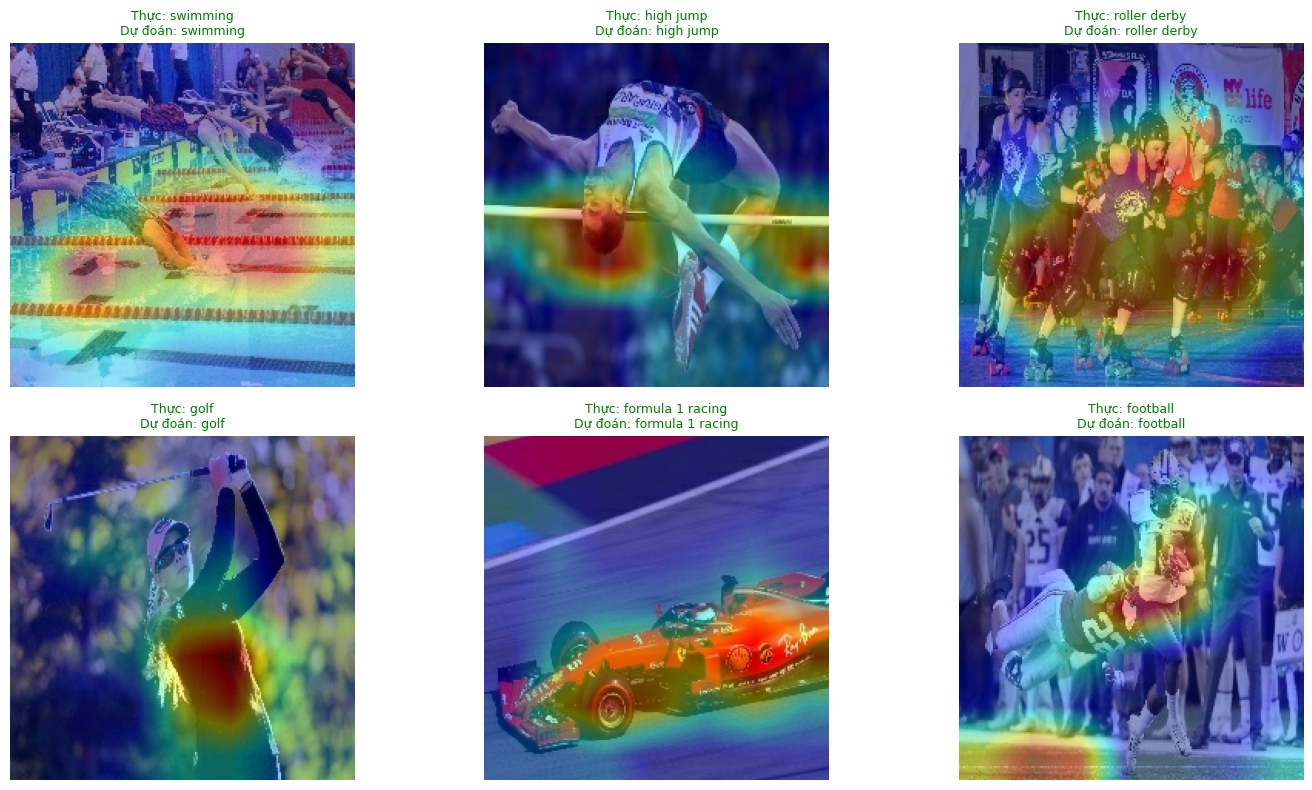

Grad-CAM — CNN_Scratch:


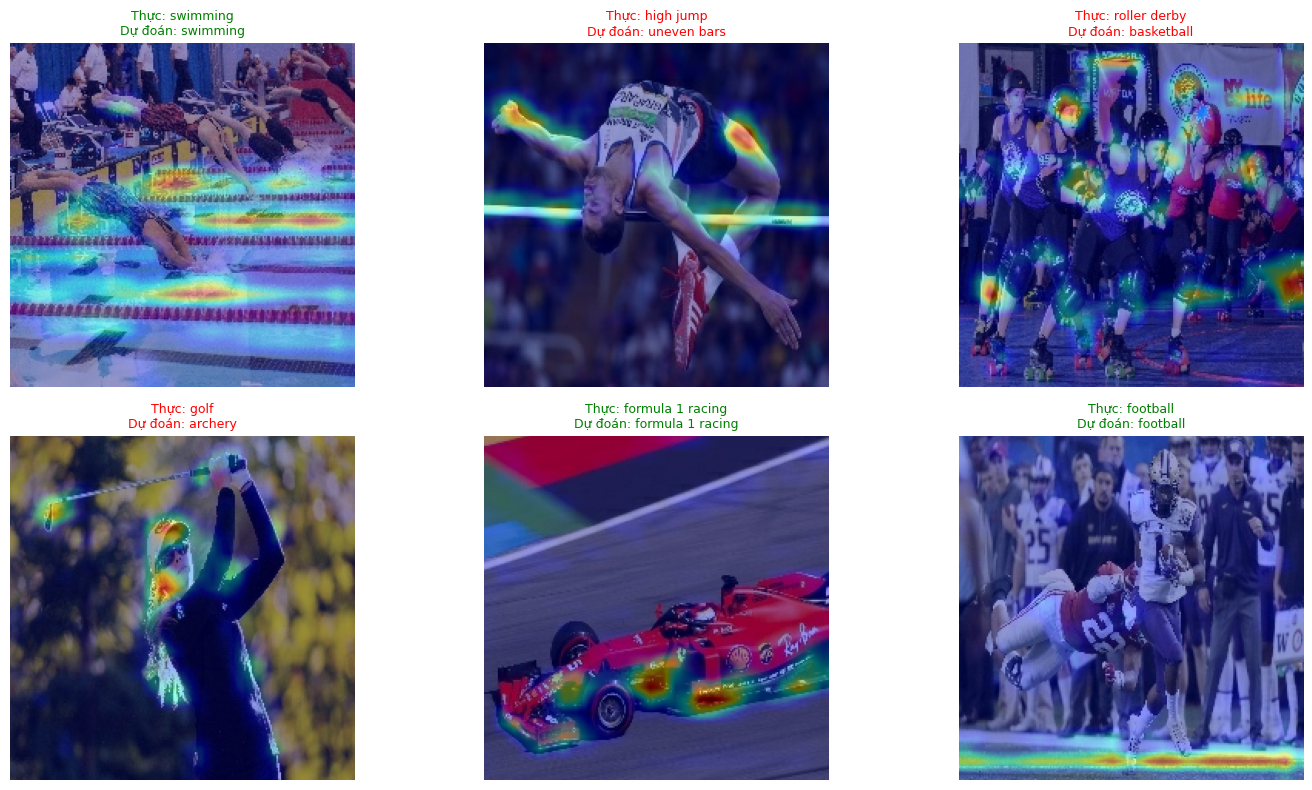

In [49]:
m_mnv2_cam = get_or_load_named_model("mobilenet_model", ["MobileNetV2_finetune_best.keras"])
if m_mnv2_cam is not None:
    print("Grad-CAM — MobileNetV2:")
    show_gradcam_examples(m_mnv2_cam, test_ds_raw, mnv2_preprocess, CLASS_NAMES, n=6, seed=SEED)
else:
    print("Chưa có mobilenet_model trong bộ nhớ và không tìm thấy MobileNetV2_finetune_best.keras.")

m_res_cam = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"])
if m_res_cam is not None:
    print("Grad-CAM — ResNet50:")
    show_gradcam_examples(m_res_cam, test_ds_raw, resnet_preprocess, CLASS_NAMES, n=6, seed=SEED)
else:
    print("Chưa có resnet_model trong bộ nhớ và không tìm thấy ResNet50_finetune_best.keras.")

m_cnn_cam = get_or_load_named_model("cnn_scratch", ["cnn_scratch_best.keras"])
if m_cnn_cam is not None:
    print("Grad-CAM — CNN_Scratch:")
    show_gradcam_examples(m_cnn_cam, test_ds_raw, None, CLASS_NAMES, n=6, seed=SEED)
else:
    print("Chưa có cnn_scratch trong bộ nhớ và không tìm thấy cnn_scratch_best.keras.")